In [1]:
%matplotlib inline

# Solution 5 (optional) — RF and quantum radiation

Install an RF cavity in the DBA ring, plot the momentum variation around the ring, and track a displaced particle with mean and quantum radiation.

See the [Xsuite synchrotron-radiation example](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html).

### Load the ring

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

ring = xt.load('ring_dba.json')
env = ring.env

Loading line from dict:   0%|          | 0/208 [00:00<?, ?it/s]

Done loading line from dict.           


### Install an RF cavity

Use a voltage of 1 MV and harmonic number $h=400$, with $f_{\mathrm{RF}}=h\beta_0c/C$. Place the cavity halfway around the ring with `phase=np.pi`.

In [3]:
env.new('rf', xt.Cavity, voltage=1e6, harmonic=400, phase=np.pi)

'rf'

In [4]:
ring.insert('rf', at=ring.get_length() / 2)

Slicing line:   0%|          | 0/384 [00:00<?, ?it/s]

### Enable mean radiation

Use `model='mean'` for average radiation losses (no quantum excitation).

In [5]:
ring.configure_radiation(model='mean')

### Twiss 6d

In [6]:
tw_rad = ring.twiss6d()

### Momentum variation around the ring

Plot $\delta=(p-p_0)/p_0$ with mean radiation. Where does the particle lose and regain energy?

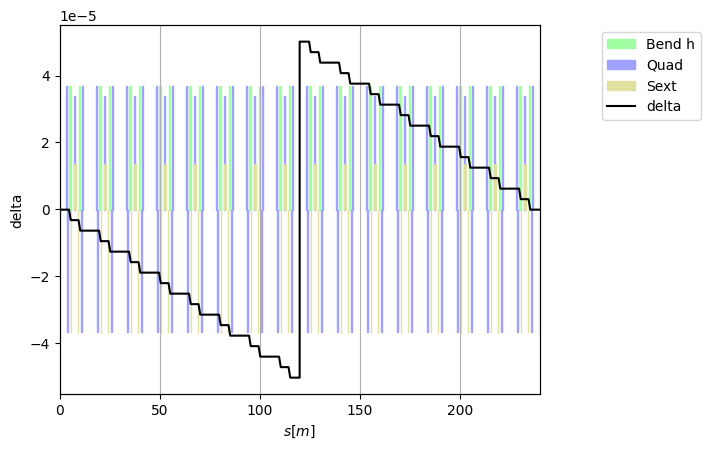

In [7]:
tw_rad.plot('delta')

### Track with mean radiation

Start from closed orbit and add 2 mm offsets in x and y and a momentum offset of 0.003. Track for 80000 turns.

In [8]:
# Make a copy of the particle on the closed orbit
p = tw_rad.particle_on_co.copy()

In [9]:
# Shift the particle from the closed orbit
p.x += 2e-3  # m
p.y += 2e-3  # m
p.delta += 3e-3

# Save the initial state
p0 = p.copy()

In [10]:
# Track
ring.track(p, num_turns=80000, turn_by_turn_monitor=True, with_progress=True)

Tracking:   0%|          | 0/80000 [00:00<?, ?it/s]

In [11]:
# Extract turn-by-turn data
mon_mean = ring.record_last_track

### Observe damping

Plot x, y, and delta at the observation point.

In [ ]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 7))

axes[0].plot(mon_mean.at_turn[0, :], mon_mean.x[0, :], linewidth=0.5)
axes[0].set_ylabel(r'$x$ [m]')

axes[1].plot(mon_mean.at_turn[0, :], mon_mean.y[0, :], linewidth=0.5)
axes[1].set_ylabel(r'$y$ [m]')

axes[2].plot(mon_mean.at_turn[0, :], mon_mean.delta[0, :], linewidth=0.5)
axes[2].set_ylabel(r'$\delta$')

axes[2].set_xlabel('Turn')
plt.tight_layout()

### Switch to quantum radiation

Use `model='quantum'` to include random photon emission. Start from the same initial particle and track for the same number of turns.

In [13]:
ring.configure_radiation(model='quantum')

In [14]:
p = p0.copy()
ring.track(p, num_turns=80000, turn_by_turn_monitor=True, with_progress=True)
mon_quantum = ring.record_last_track

Tracking:   0%|          | 0/80000 [00:00<?, ?it/s]

### Compare mean and quantum radiation

Which oscillations continue to fluctuate after damping? Why is the vertical plane different from the others?

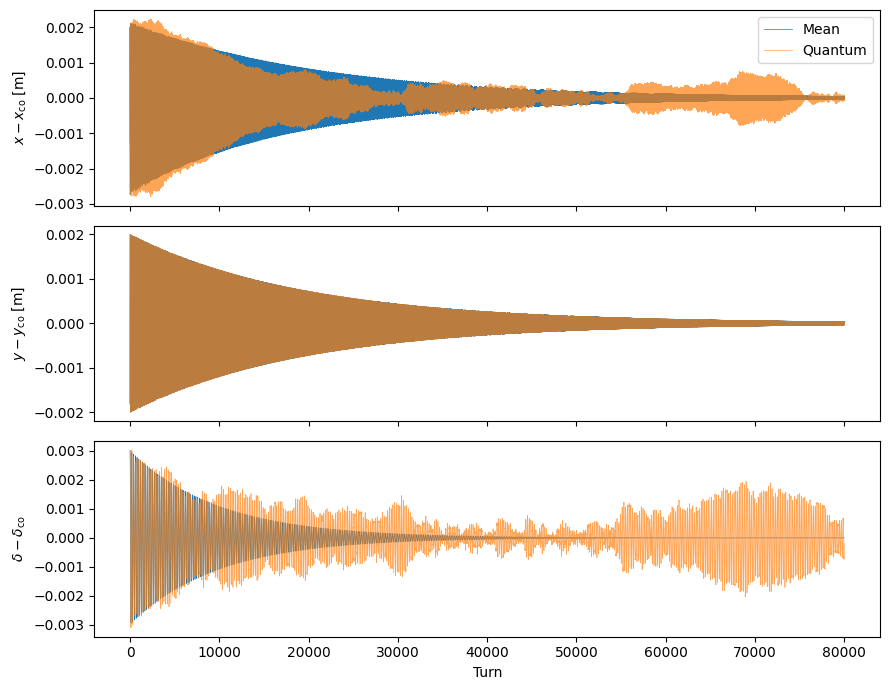

In [15]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 7))

axes[0].plot(mon_mean.at_turn[0], mon_mean.x[0], linewidth=0.5, label='Mean')
axes[0].plot(mon_quantum.at_turn[0], mon_quantum.x[0], linewidth=0.5, alpha=0.7, label='Quantum')
axes[0].set_ylabel(r'$x$ [m]')
axes[0].legend()

axes[1].plot(mon_mean.at_turn[0], mon_mean.y[0], linewidth=0.5)
axes[1].plot(mon_quantum.at_turn[0], mon_quantum.y[0], linewidth=0.5, alpha=0.7)
axes[1].set_ylabel(r'$y$ [m]')

axes[2].plot(mon_mean.at_turn[0], mon_mean.delta[0], linewidth=0.5)
axes[2].plot(mon_quantum.at_turn[0], mon_quantum.delta[0], linewidth=0.5, alpha=0.7)
axes[2].set_ylabel(r'$\delta$')
axes[2].set_xlabel('Turn')
plt.tight_layout()